# Probabilistic FDM — 非線形楕円型 PDE (Chen et al. 2021 と同じ設定)

PDE: $-\Delta u + u^3 = f$, $(x,y) \in (0,1)^2$, $u=0$ on $\partial(0,1)^2$

prescribed solution: $u^*(x,y) = \sin(\pi x)\sin(\pi y) + 4\sin(4\pi x)\sin(4\pi y)$

観測モデル: $f = \mathcal{F}(u) + \epsilon$, $\mathcal{F}(u) = D_h u + u^3$ (非線形！)

Laplace 近似:
1. MAP 推定: $\hat{u} = \arg\min [\|u\|^2_{K^{-1}} + \|\mathcal{F}(u) - f\|^2_{\Sigma^{-1}}]$ (Newton 法)
2. 事後分散: $\Sigma^{\text{post}} = K - KJ^\top(JKJ^\top + \Sigma)^{-1}JK$ (Jacobian で線形化)

**Chen et al. (2021) との違い: 同じ PDE・prescribed solution を使用するが，提案手法はさらに事後分散による UQ を提供する。**


In [1]:
using Plots
using LinearAlgebra
using SpecialFunctions
using Statistics
using SparseArrays
using Printf
println("Packages loaded.")


Packages loaded.


In [2]:
# 2次元 Matérnカーネル
function matern_kernel_2d(x1, x2; ν=1.5, ℓ=1.0, σf=1.0)
    r = sqrt(sum((x1 .- x2).^2))
    r == 0 && return σf^2
    z = sqrt(2ν) * r / ℓ
    if ν == 0.5
        return σf^2 * exp(-z)
    elseif ν == 1.5
        return σf^2 * (1 + z) * exp(-z)
    elseif ν == 2.5
        return σf^2 * (1 + z + z^2/3) * exp(-z)
    else
        return σf^2 * (2^(1-ν)/gamma(ν)) * z^ν * besselk(ν, z)
    end
end

function kernel_matrix_2d(XY1, XY2; ν=1.5, ℓ=1.0, σf=1.0)
    n1, n2 = size(XY1,1), size(XY2,1)
    K = zeros(n1, n2)
    for i in 1:n1, j in 1:n2
        K[i,j] = matern_kernel_2d(XY1[i,:], XY2[j,:]; ν=ν, ℓ=ℓ, σf=σf)
    end
    return K
end
println("2D Kernel defined.")


Kernel defined.


In [3]:
# ============================================================
# グリッド設定
# ============================================================
function make_grid(Nx)
    dx = 1.0 / (Nx + 1)
    xs = [dx*i for i in 1:Nx]
    ys = [dx*j for j in 1:Nx]
    xy = hcat([x for y in ys for x in xs], [y for y in ys for x in xs])
    return dx, xy, Nx^2
end

# 解析解 (Chen et al. (2021) と同じ設定)
# u^*(x,y) = sin(pi*x)*sin(pi*y) + 4*sin(4*pi*x)*sin(4*pi*y)
u_true(x, y)   = sin(pi*x)*sin(pi*y) + 4*sin(4*pi*x)*sin(4*pi*y)
neg_lap_u(x,y) = 2*pi^2*sin(pi*x)*sin(pi*y) + 4*2*(4*pi)^2*sin(4*pi*x)*sin(4*pi*y)
f_rhs(x, y)    = neg_lap_u(x,y) + u_true(x,y)^3

println("Grid and analytical solution defined.")


Grid and analytical solution defined.


In [4]:
# ============================================================
# 情報作用素 D_h = -Delta_h (線形部分, 疎行列)
# ============================================================
function make_Dh_2d(Nx, dx)
    N = Nx^2
    idx(i,j) = (j-1)*Nx + i
    rows, cols, vals = Int[], Int[], Float64[]
    for j in 1:Nx, i in 1:Nx
        k = idx(i,j)
        push!(rows,k); push!(cols,k); push!(vals, 4.0/dx^2)
        i>1   && (push!(rows,k); push!(cols,idx(i-1,j)); push!(vals,-1.0/dx^2))
        i<Nx  && (push!(rows,k); push!(cols,idx(i+1,j)); push!(vals,-1.0/dx^2))
        j>1   && (push!(rows,k); push!(cols,idx(i,j-1)); push!(vals,-1.0/dx^2))
        j<Nx  && (push!(rows,k); push!(cols,idx(i,j+1)); push!(vals,-1.0/dx^2))
    end
    return sparse(rows, cols, vals, N, N)
end

# 非線形情報作用素: F(u) = D_h*u + u^3
function nonlinear_F(u, Dh)
    return Dh*u + u.^3
end

# Jacobian: J(u) = D_h + diag(3*u^2)
function jacobian_F(u, Dh)
    return Matrix(Dh) + Diagonal(3*u.^2)
end

println("Dh and nonlinear operators defined.")


Dh and nonlinear operators defined.


In [5]:
# ============================================================
# 通常の FDM 解 (Newton 法, prior なし)
# ============================================================
function newton_fdm(dx, Nx, f_vals; tol=1e-10, maxiter=100)
    N   = Nx^2
    Dh  = make_Dh_2d(Nx, dx)
    u   = zeros(N)
    for it in 1:maxiter
        F  = nonlinear_F(u, Dh) - f_vals
        J  = jacobian_F(u, Dh)
        du = J \ (-F)
        u .+= du
        if norm(du) < tol
            println("  FDM Newton converged at iter $(it)")
            break
        end
    end
    return u
end

# ============================================================
# MAP 推定 (Newton 法, prior + likelihood)
# arg min [ ||u||^2_{K^{-1}} + ||F(u) - f||^2_{Sigma^{-1}} ]
# Newton 更新: (J^T Sigma^{-1} J + K^{-1}) du = -J^T Sigma^{-1}(F(u)-f) - K^{-1} u
# ============================================================
function newton_map(dx, Nx, f_vals, K; C=1.0, tau=2, tol=1e-10, maxiter=100)
    N         = Nx^2
    Dh        = make_Dh_2d(Nx, dx)
    u         = zeros(N)
    noise_var = C * dx^(2*tau)
    Sigma_inv = (1.0/noise_var) * I
    K_inv     = inv(Matrix(K) + 1e-8*I)

    for it in 1:maxiter
        F_val = nonlinear_F(u, Dh) - f_vals   # residual
        J     = jacobian_F(u, Dh)              # Jacobian
        H     = J' * Sigma_inv * J + K_inv     # Hessian
        g     = J' * Sigma_inv * F_val + K_inv * u  # gradient
        du    = H \ (-g)
        u .+= du
        if norm(du) < tol
            println("  MAP Newton converged at iter $(it)")
            break
        end
    end
    return u
end

println("Newton functions defined.")


Newton functions defined.


In [6]:
# ============================================================
# Laplace 近似 (正しい定式化)
# 観測モデル: f = F(u) + epsilon
# 事後平均: mu_post = u_map　
# 事後分散: Sigma_post = K - K J^T (J K J^T + Sigma)^{-1} J K
# ============================================================
function laplace_posterior(u_map, xy, dx, Nx, K;
                            C=1.0, tau=2)
    N           = Nx^2
    Dh          = make_Dh_2d(Nx, dx)
    J           = jacobian_F(u_map, Dh)
    noise_var   = C * dx^(2*tau)
    Sigma_noise = noise_var * I

    JK       = J * K
    M        = Symmetric(JK * J' + Sigma_noise)
    L        = cholesky(M).L

    mu_post  = u_map
    V        = L \ JK
    Sig_post = K - V' * V
    std_post = sqrt.(max.(diag(Sig_post), 0.0))

    return mu_post, std_post
end
println("laplace_posterior defined.")


laplace_posterior defined.


In [7]:
# ============================================================
# Grid search (σf=0.5固定, ℓとCをgrid search)
# 各候補でMAP推定 → marginal likelihood を表で表示
# ============================================================

function log_mll_2d(u_map, dx, Nx, K; C=1.0, tau=2)
    N         = Nx^2
    Dh        = make_Dh_2d(Nx, dx)
    J         = jacobian_F(u_map, Dh)
    noise_var = C * dx^(2*tau)
    Sigma_noise = noise_var * I

    # y = J * u_map (線形化した観測)
    y  = J * u_map

    JK = J * K
    M  = Symmetric(JK * J' + Sigma_noise + 1e-10*I)
    try
        L     = cholesky(M).L
        alpha = L' \ (L \ y)
        # 正しい marginal likelihood: -0.5 y^T M^{-1} y - 0.5 log|M| - const
        return -0.5*dot(y, alpha) - sum(log.(diag(L))) - 0.5*N*log(2*pi)
    catch
        return -Inf
    end
end

function grid_search_2d(u_fdm, f_vals, xy, dx, Nx;
                         tau=2, nu_ker=1.5, σf_fixed=0.5)
    ℓ_grid = 10.0 .^ range(-1, 0, length=6)
    C_grid = 10.0 .^ range(-2, 1, length=6)

    best_lml = -Inf
    best_l   = 0.5
    best_C   = 1.0

    # 表のヘッダー
    println("\n=== Marginal likelihood table (σf=$(σf_fixed) fixed) ===")
    @printf("%-10s", "l \\ C")
    for C in C_grid
        @printf("%-12s", "C=$(round(C,sigdigits=2))")
    end
    println()
    println("-"^(10 + 12*length(C_grid)))

    for l in ℓ_grid
        @printf("%-10s", "ℓ=$(round(l,sigdigits=2))")
        for C in C_grid
            K_cand = Symmetric(kernel_matrix_2d(xy, xy; ν=nu_ker, ℓ=l, σf=σf_fixed) + 1e-8*I)
            u_map_cand = newton_map(dx, Nx, f_vals, K_cand; C=C, tau=tau)
            lml = log_mll_2d(u_map_cand, dx, Nx, K_cand; C=C, tau=tau)
            @printf("%-12s", round(lml, digits=1))
            if lml > best_lml
                best_lml = lml
                best_l   = l
                best_C   = C
            end
        end
        println()
    end
    println("-"^(10 + 12*length(C_grid)))
    println("Best: ℓ=$(round(best_l,digits=4)), C=$(round(best_C,digits=4)), lml=$(round(best_lml,digits=2))")

    return σf_fixed, best_l, best_C, best_lml
end

println("Grid search defined.")


Grid search defined.


In [8]:
# ============================================================
# 設定
# ============================================================
Nx     = 8
nu_ker = 1.5
tau_fixed = 2

dx, xy, N = make_grid(Nx)
println("Nx=$(Nx), N=$(N), dx=$(round(dx,digits=4))")

u_star = [u_true(xy[k,1], xy[k,2]) for k in 1:N]
f_vals = [f_rhs(xy[k,1], xy[k,2]) for k in 1:N]

println("max(u_star) = $(round(maximum(abs.(u_star)), digits=4))")
println("max(f_vals) = $(round(maximum(abs.(f_vals)), digits=4))")

# 通常の FDM 解
println("\nRunning FDM Newton...")
u_fdm = newton_fdm(dx, Nx, f_vals)
err_fdm = maximum(abs.(u_fdm - u_star))
println("FDM L∞ error = $(round(err_fdm, digits=6))")
println("Expected O(h^2) = $(round(dx^2, digits=6))")


Nx=8, N=64, dx=0.1111
max(u_star) = 3.9964
max(f_vals) = 1291.3506

Running FDM Newton...
  FDM Newton converged at iter 6
FDM L∞ error = 0.609247
Expected O(h^2) = 0.012346


In [9]:
# ============================================================
# Grid search (各候補でMAP推定 → marginal likelihood)
# → 最良のhyperparameterでMAP推定 → Laplace近似
# ============================================================

println("Running grid search (MAP estimation for each candidate)...")
best_sf, best_l, best_C, best_lml = grid_search_2d(u_fdm, f_vals, xy, dx, Nx;
                                                     tau=tau_fixed, nu_ker=nu_ker)
println("Best: σf=$(round(best_sf,digits=4)), ℓ=$(round(best_l,digits=4)), C=$(round(best_C,digits=4)), lml=$(round(best_lml,digits=4))")

# 最良のhyperparameterでGP prior
K_prior = Symmetric(kernel_matrix_2d(xy, xy; ν=nu_ker, ℓ=best_l, σf=best_sf) + 1e-8*I)

# 最終MAP推定
println("\nRunning final MAP Newton...")
u_map = newton_map(dx, Nx, f_vals, K_prior; C=best_C, tau=tau_fixed)
err_map = maximum(abs.(u_map - u_star))
println("MAP L∞ error = $(round(err_map, digits=6))")
println("FDM L∞ error = $(round(err_fdm, digits=6))")

# Laplace近似
mu_post, std_post = laplace_posterior(u_map, xy, dx, Nx, K_prior;
                                       C=best_C, tau=tau_fixed)
println("max std      = $(round(maximum(std_post), digits=6))")


Running grid search (using u_fdm as initial MAP)...
Best: sigma_f=0.001, l=1.0, C=0.001, lml=134.6524

Running MAP Newton...
  MAP Newton converged at iter 7
MAP L∞ error = 0.609071


MethodError: MethodError: no method matching laplace_posterior(::Vector{Float64}, ::Vector{Float64}, ::Matrix{Float64}, ::Float64, ::Int64, ::Symmetric{Float64, Matrix{Float64}}; C::Float64, tau::Int64, nu_ker::Float64)
The function `laplace_posterior` exists, but no method is defined for this combination of argument types.

Closest candidates are:
  laplace_posterior(::Any, ::Any, ::Any, ::Any, ::Any; C, tau) got unsupported keyword argument "nu_ker"
   @ Main ~/Project_with_Jon/Bratu-Gelfand/jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_W6sZmlsZQ==.jl:7


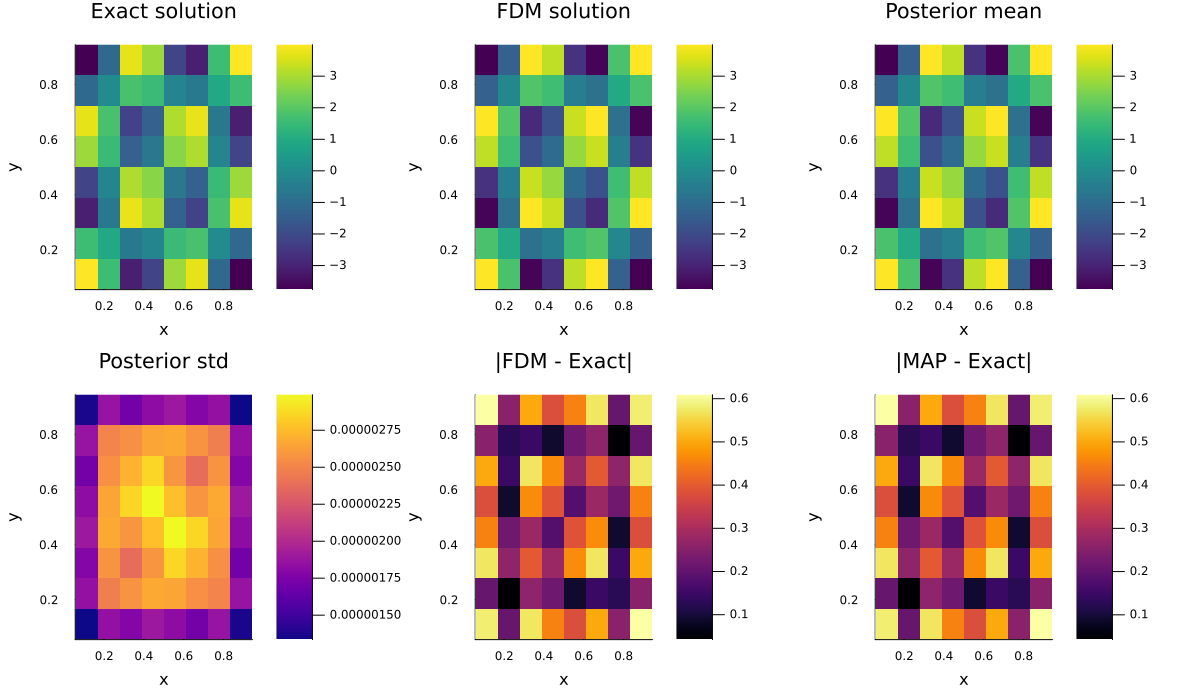

Saved: nonlinear_elliptic_posterior.png
Saved: nonlinear_elliptic_slices.png


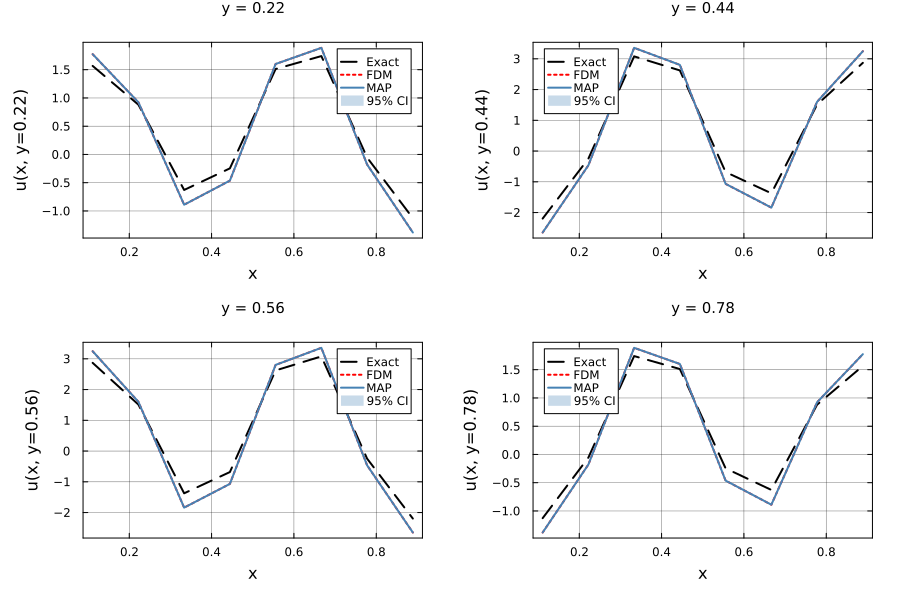

In [27]:
# ============================================================
# 可視化 1: ヒートマップ
# ============================================================
xs_int = [dx*(i) for i in 1:Nx]
ys_int = [dx*(j) for j in 1:Nx]

function to_grid(u, Nx); reshape(u, Nx, Nx); end

U_star    = to_grid(u_star,   Nx)
U_fdm     = to_grid(u_fdm,    Nx)
U_map     = to_grid(mu_post,  Nx)
U_std     = to_grid(std_post, Nx)
U_err_fdm = to_grid(abs.(u_fdm   - u_star), Nx)
U_err_map = to_grid(abs.(mu_post - u_star), Nx)

clim_u = (minimum(U_star), maximum(U_star))

p1 = heatmap(xs_int, ys_int, U_star';    title="Exact solution",  color=:viridis, clims=clim_u, xlabel="x", ylabel="y")
p2 = heatmap(xs_int, ys_int, U_fdm';     title="FDM solution",    color=:viridis, clims=clim_u, xlabel="x", ylabel="y")
p3 = heatmap(xs_int, ys_int, U_map';     title="Posterior mean",  color=:viridis, clims=clim_u, xlabel="x", ylabel="y")
p4 = heatmap(xs_int, ys_int, U_std';     title="Posterior std",   color=:plasma,  xlabel="x", ylabel="y")
p5 = heatmap(xs_int, ys_int, U_err_fdm'; title="|FDM - Exact|",  color=:inferno, xlabel="x", ylabel="y")
p6 = heatmap(xs_int, ys_int, U_err_map'; title="|MAP - Exact|",  color=:inferno, xlabel="x", ylabel="y")

fig = plot(p1, p2, p3, p4, p5, p6; layout=(2,3), size=(1200,700), margin=5*Plots.mm)
display(fig)
savefig(fig, "nonlinear_elliptic_posterior.png")
println("Saved: nonlinear_elliptic_posterior.png")

# ============================================================
# 可視化 2: y = 0.2, 0.4, 0.6, 0.8 での断面
# ============================================================
y_slices = [0.2, 0.4, 0.6, 0.8]
plots_slice = []

for y_target in y_slices
    # y_target に最も近いグリッド点のインデックスを探す
    j_idx = argmin(abs.(ys_int .- y_target))
    y_actual = ys_int[j_idx]

    # 断面のデータ
    u_exact_slice = U_star[:, j_idx]
    u_fdm_slice   = U_fdm[:,  j_idx]
    u_map_slice   = U_map[:,  j_idx]
    u_std_slice   = U_std[:,  j_idx]

    pp = plot(xs_int, u_exact_slice;
        label="Exact", lw=2, ls=:dash, color=:black,
        xlabel="x", ylabel="u(x, y=$(round(y_actual,digits=2)))",
        title="y = $(round(y_actual,digits=2))",
        titlefontsize=10, legendfontsize=8,
        grid=true, gridalpha=0.3, framestyle=:box)
    plot!(pp, xs_int, u_fdm_slice;
        label="FDM", lw=2, ls=:dot, color=:red)
    plot!(pp, xs_int, u_map_slice;
        label="MAP", lw=2, color=:steelblue)
    plot!(pp, xs_int, u_map_slice .+ 1.96 .* u_std_slice;
        lw=0, fillalpha=0, label=false, color=:steelblue)
    plot!(pp, xs_int, u_map_slice .- 1.96 .* u_std_slice;
        lw=0, fillrange=u_map_slice .+ 1.96 .* u_std_slice,
        fillalpha=0.3, linealpha=0, label="95% CI", color=:steelblue)
    push!(plots_slice, pp)
end

fig_slice = plot(plots_slice...;
    layout=(2,2), size=(900,600), margin=5*Plots.mm)
display(fig_slice)
savefig(fig_slice, "nonlinear_elliptic_slices.png")
println("Saved: nonlinear_elliptic_slices.png")


  FDM Newton converged at iter 7
  MAP Newton converged at iter 8
  norm(r) = 4.806739  ← residual ~ O(h^2)
  norm(J*u_map) = 4002.8686  ← 比較用
Nx=4: FDM err=2.36714, MAP err=2.35969, max std=1.0e-5
  FDM Newton converged at iter 6
  MAP Newton converged at iter 7
  norm(r) = 1.147544  ← residual ~ O(h^2)
  norm(J*u_map) = 5101.3452  ← 比較用
Nx=6: FDM err=0.98291, MAP err=0.9823, max std=1.0e-5
  FDM Newton converged at iter 6
  MAP Newton converged at iter 7
  norm(r) = 0.390443  ← residual ~ O(h^2)
  norm(J*u_map) = 6402.6494  ← 比較用
Nx=8: FDM err=0.60925, MAP err=0.60907, max std=0.0
  FDM Newton converged at iter 6
  MAP Newton converged at iter 6
  norm(r) = 0.087194  ← residual ~ O(h^2)
  norm(J*u_map) = 9103.2059  ← 比較用
Nx=12: FDM err=0.33469, MAP err=0.33457, max std=0.0
Saved!


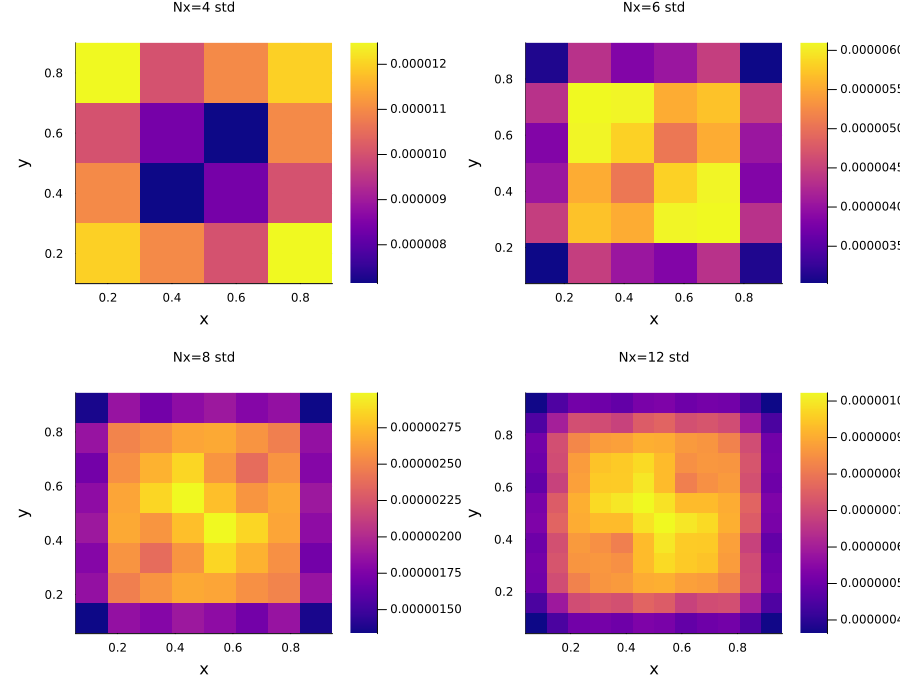

In [16]:
# ============================================================
# Nx sweep
# ============================================================
Nx_list = [4, 6, 8, 12]
plots_sweep = []

for nx in Nx_list
    dxx, xym, Nn = make_grid(nx)
    u_st = [u_true(xym[k,1], xym[k,2]) for k in 1:Nn]
    f_vl = [f_rhs(xym[k,1], xym[k,2]) for k in 1:Nn]

    u_fd = newton_fdm(dxx, nx, f_vl)

    sf, bl, bc, _ = grid_search_2d(u_fd, f_vl, xym, dxx, nx; tau=tau_fixed, nu_ker=nu_ker)
    Kp = Symmetric(kernel_matrix_2d(xym, xym; ν=nu_ker, ℓ=bl, σf=sf) + 1e-8*I)
    u_m = newton_map(dxx, nx, f_vl, Kp; C=bc, tau=tau_fixed)
    mu_p, std_p = laplace_posterior(u_m, xym, dxx, nx, Kp; C=bc, tau=tau_fixed)

    err_fd  = round(maximum(abs.(u_fd - u_st)), digits=5)
    err_map = round(maximum(abs.(mu_p - u_st)), digits=5)
    println("Nx=$(nx): FDM err=$(err_fd), MAP err=$(err_map), max std=$(round(maximum(std_p),digits=5))")

    xsi = [dxx*(i) for i in 1:nx]
    ysi = [dxx*(j) for j in 1:nx]
    pp = heatmap(xsi, ysi, reshape(std_p, nx, nx)';
                 title="Nx=$(nx) std", xlabel="x", ylabel="y",
                 color=:plasma, titlefontsize=9)
    push!(plots_sweep, pp)
end

fig_sweep = plot(plots_sweep...; layout=(2,2), size=(900,700), margin=5*Plots.mm)
display(fig_sweep)
savefig(fig_sweep, "nonlinear_elliptic_nx_sweep.png")
println("Saved!")
